# Какие аугментации помогают LeNet?

Сначала попробуем каждую аугментацию отдельно, а потом соберём несколько сочетаний. Так будет проще понять, что помогает модели. Во всех запусках для сохранения честности эксперимента зафиксируем: seed **52**, одно разбиение train/val и одинаковые начальные веса.

Эксперимент состоит из четырёх этапов:

1. **Отдельные аугментации, 100 эпох.** Сравним каждое преобразование с обучением без аугментаций и выберем до четырёх кандидатов.
2. **Проверка кандидатов, 300 эпох.** Обучим выбранные варианты и модель без аугментаций заново. Посмотрим, сохраняется ли преимущество при более длительном обучении.
3. **Сочетания аугментаций, 100 эпох.** Из выбранных операций составим несколько наборов: сначала две операции, затем добавим третью и четвёртую. Сравним их между собой и с отдельными преобразованиями на том же числе эпох.
4. **Полное обучение финалистов.** Проверим три лучших сочетания и обучим их заново с лимитом 1000 эпох. Обучение остановится раньше, если validation accuracy не улучшится за 50 эпох.

После каждого этапа кандидаты выбираются вручную по таблицам и графикам. Их названия записываются в список перед следующим этапом.

Пустой список пропускает обучение. Когда выбор уже сделан, достаточно выполнить ячейки нужного раздела

In [1]:
from functools import partial
from pathlib import Path
import sys

import torch
from torch import nn
from torch.utils.data import TensorDataset
from torchvision.transforms import v2

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_utils import images_to_tensor, train_dataset_split
from utils.data_utils import calculate_mean_std, standardize_batch
from utils.lenet_experiments import LeNet5, new_results_dir, show_examples
from utils.lenet_experiments import run_lenet_experiment, experiment_table
from utils.lenet_experiments import plot_learning_curves, select_transforms, cumulative_combinations
from utils.lenet_experiments import completed_transforms

## Общие настройки

Используем ту же архитектуру LeNet-5, что и в [основном ноутбуке](LeNet.ipynb), и оптимизатор Adam. В каждом запуске сохраняем веса с лучшей validation accuracy.


In [3]:
SEED = 52
TRAIN_FRACTION = 0.8
BATCH_SIZE = 512
NUM_WORKERS = 4
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

SCREEN_EPOCHS = 100
CHECK_EPOCHS = 300
FINAL_EPOCHS = 1000
FINAL_PATIENCE = 50

In [4]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print(DEVICE)

mps


## Подготовим данные

Один раз разделим данные: 80% на train, 20% на validation. Среднее и стандартное отклонение считаем только по train. Validation стандартизируем сразу и больше не меняем. Картинки train сначала аугментируем, а затем стандартизируем батчами.

In [5]:
X_train, y_train = images_to_tensor(
    PROJECT_ROOT / "data/train", PROJECT_ROOT / "data/trainLabels.csv",
)
ds_train, ds_val = train_dataset_split(
    TensorDataset(X_train, y_train), train_size=TRAIN_FRACTION, random_seed=SEED,
)
print(f"Train: {len(ds_train)}, validation: {len(ds_val)}")

Train: 40000, validation: 10000


In [6]:
mean, std = calculate_mean_std(ds_train)
val_images = standardize_batch(X_train[ds_val.indices], mean=mean, std=std)
ds_val_ready = TensorDataset(val_images, y_train[ds_val.indices])
fill = tuple(round(value) for value in mean.tolist())

В `fill` записан средний цвет train, значения каналов здесь от 0 до 255. Этим цветом заполняем края при повороте и изменении масштаба, а также закрытый участок при маскировании.

In [7]:
LeNet5()

LeNet5(
  (network): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Tanh()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)

Ниже задаём общие параметры для всех экспериментов. В каждом запуске создаются новая модель и оптимизатор Adam. Лучшие по validation веса сохраняются в `models/`, а метрики каждой эпохи и таблица результатов в `results/lenet_augmentation/`.

При повторном запуске старые результаты не перезаписываются. Для сравнения берётся последний завершённый запуск каждого варианта с выбранным числом эпох.

Метрики также доступны в Aim, в эксперименте `lenet-augmentation`. Интерфейс запускается из корня проекта командой `aim up --repo . --port 43800`.


In [8]:
results_dir = new_results_dir(PROJECT_ROOT / "results/lenet_augmentation")
run_experiment = partial(
    run_lenet_experiment,
    ds_train=ds_train, ds_val=ds_val_ready,
    mean=mean, std=std, device=DEVICE,
    results_dir=results_dir, project_root=PROJECT_ROOT,
    seed=SEED, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    epochs=SCREEN_EPOCHS, patience=None, stage="single",
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(f"Результаты: {results_dir}")

Результаты: /Users/melikhovartem/pet_projects/CIFAR-10/results/lenet_augmentation/20261023T211312Z_5345c994


## 1. Одиночные аугментации: 100 эпох

В каждом опыте используем только одну операцию. Пока оставим одну силу и вероятность для каждой из них. Посмотрим, какие варианты стоит изучать дальше.

### Без аугментаций

Сначала обучим модель на исходных картинках. С этим результатом будем сравнивать остальные варианты.

In [9]:
baseline_transform = nn.Identity()
run_experiment("Без аугментаций", baseline_transform)

Без аугментаций: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3262
Эпоха 25/100: val_accuracy=0.5321
Эпоха 50/100: val_accuracy=0.5584
Эпоха 75/100: val_accuracy=0.5652
Эпоха 100/100: val_accuracy=0.5711
Best epoch = 100, best val_acc = 0.5711


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Без аугментаций,57.11,100


### Horizontal flip

В обучении отражаем картинку по горизонтали с вероятностью 0,5.


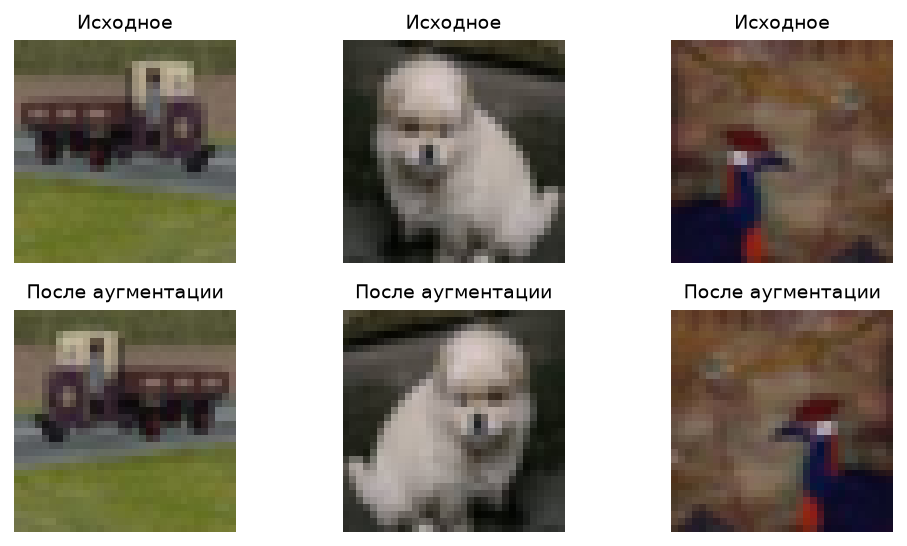

In [10]:
flip_transform = v2.RandomHorizontalFlip(p=0.5)
show_examples(ds_train, flip_transform)

In [11]:
run_experiment("Horizontal flip", flip_transform)

Horizontal flip: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3238
Эпоха 25/100: val_accuracy=0.5335
Эпоха 50/100: val_accuracy=0.5693
Эпоха 75/100: val_accuracy=0.5847
Эпоха 100/100: val_accuracy=0.5937
Best epoch = 98, best val_acc = 0.5948


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Horizontal flip,59.48,98


### Crop

С вероятностью 0,5 добавляем отражающий padding на 4 пикселя и выбираем случайное окно 32×32. Картинка остаётся того же размера, но объект немного сдвигается.

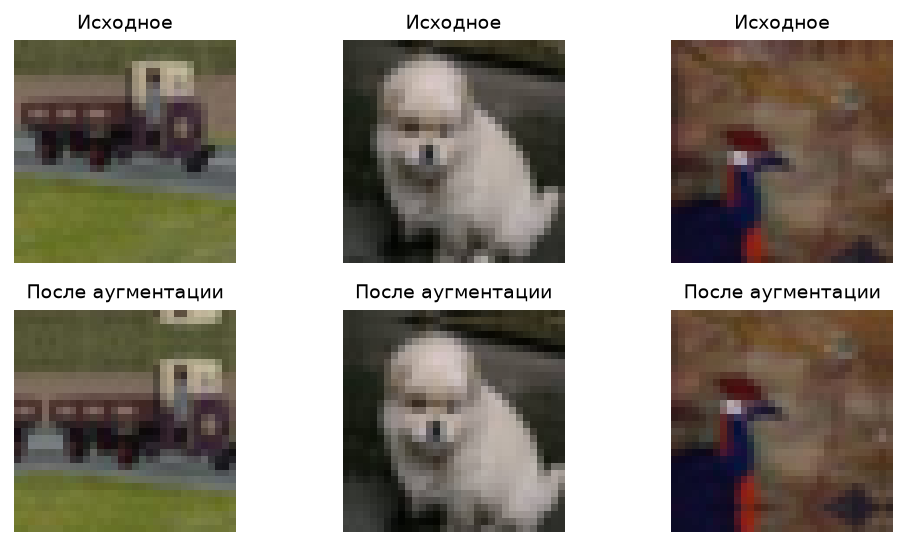

In [12]:
crop_transform = v2.RandomApply([
    v2.RandomCrop(32, padding=4, padding_mode="reflect"),
], p=0.5)
show_examples(ds_train, crop_transform)

In [13]:
run_experiment("Crop", crop_transform)

Crop: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3234
Эпоха 25/100: val_accuracy=0.5274
Эпоха 50/100: val_accuracy=0.5609
Эпоха 75/100: val_accuracy=0.5756
Эпоха 100/100: val_accuracy=0.5875
Best epoch = 99, best val_acc = 0.5901


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Crop,59.01,99


### Яркость

С вероятностью 0,5 делаем картинку чуть темнее или светлее. Множитель яркости выбирается от 0,8 до 1,2. Контраст и насыщенность здесь не меняем.

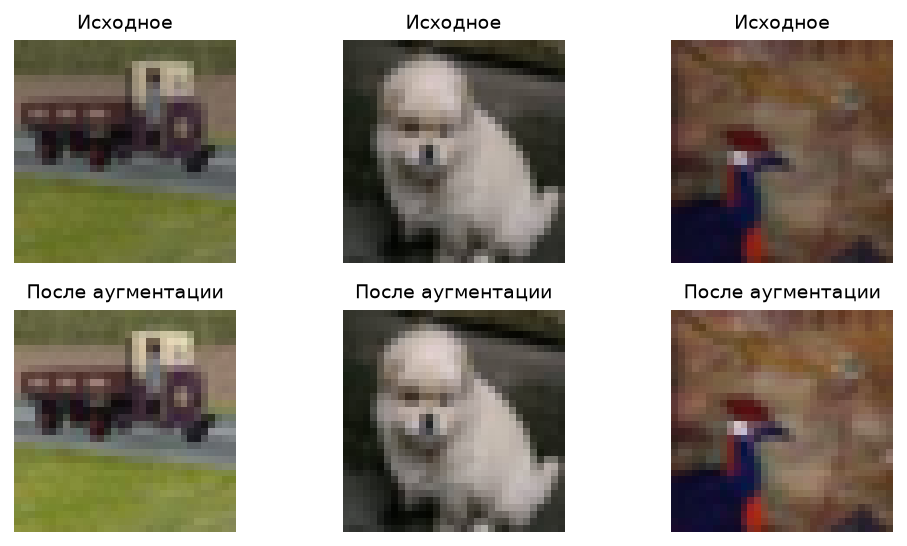

In [14]:
brightness_transform = v2.RandomApply([
    v2.ColorJitter(brightness=0.2),
], p=0.5)
show_examples(ds_train, brightness_transform)

In [15]:
run_experiment("Brightness", brightness_transform)

Brightness: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3244
Эпоха 25/100: val_accuracy=0.5321
Эпоха 50/100: val_accuracy=0.5539
Эпоха 75/100: val_accuracy=0.5661
Эпоха 100/100: val_accuracy=0.5749
Best epoch = 100, best val_acc = 0.5749


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Brightness,57.49,100


### Контраст

Теперь отдельно попробуем менять контраст. Множитель выбирается от 0,8 до 1,2, вероятность применения равна 0,5.

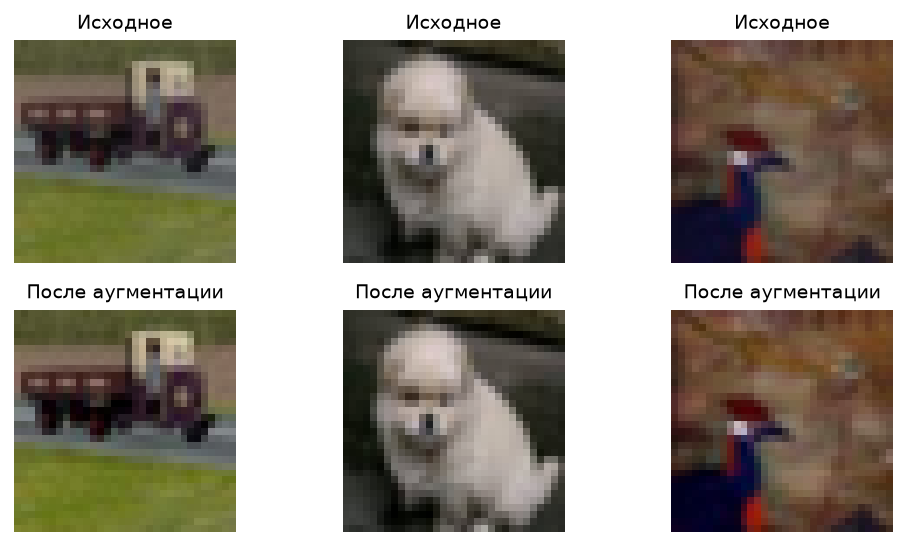

In [16]:
contrast_transform = v2.RandomApply([
    v2.ColorJitter(contrast=0.2),
], p=0.5)
show_examples(ds_train, contrast_transform)

In [17]:
run_experiment("Contrast", contrast_transform)

Contrast: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3268
Эпоха 25/100: val_accuracy=0.5312
Эпоха 50/100: val_accuracy=0.5580
Эпоха 75/100: val_accuracy=0.5654
Эпоха 100/100: val_accuracy=0.5706
Best epoch = 81, best val_acc = 0.5707


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Contrast,57.07,81


### Насыщенность

С вероятностью 0,5 меняем насыщенность в пределах от 0,8 до 1,2 от исходной. Посмотрим, помогает ли небольшое изменение интенсивности цвета.

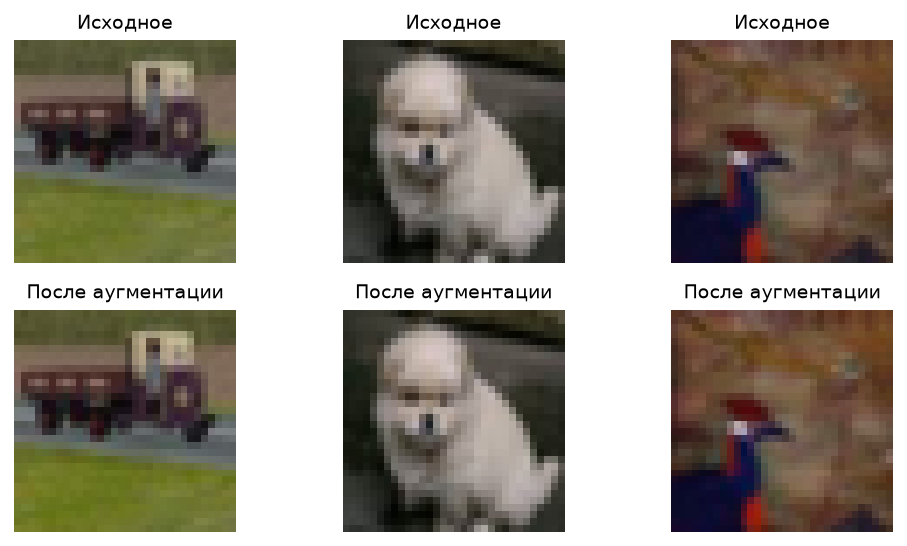

In [18]:
saturation_transform = v2.RandomApply([
    v2.ColorJitter(saturation=0.2),
], p=0.5)
show_examples(ds_train, saturation_transform)

In [19]:
run_experiment("Saturation", saturation_transform)

Saturation: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3266
Эпоха 25/100: val_accuracy=0.5320
Эпоха 50/100: val_accuracy=0.5579
Эпоха 75/100: val_accuracy=0.5655
Эпоха 100/100: val_accuracy=0.5718
Best epoch = 100, best val_acc = 0.5718


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Saturation,57.18,100


### Небольшой поворот

С вероятностью 0,5 поворачиваем картинку на случайный угол от -10° до +10°. Размер оставляем 32×32.

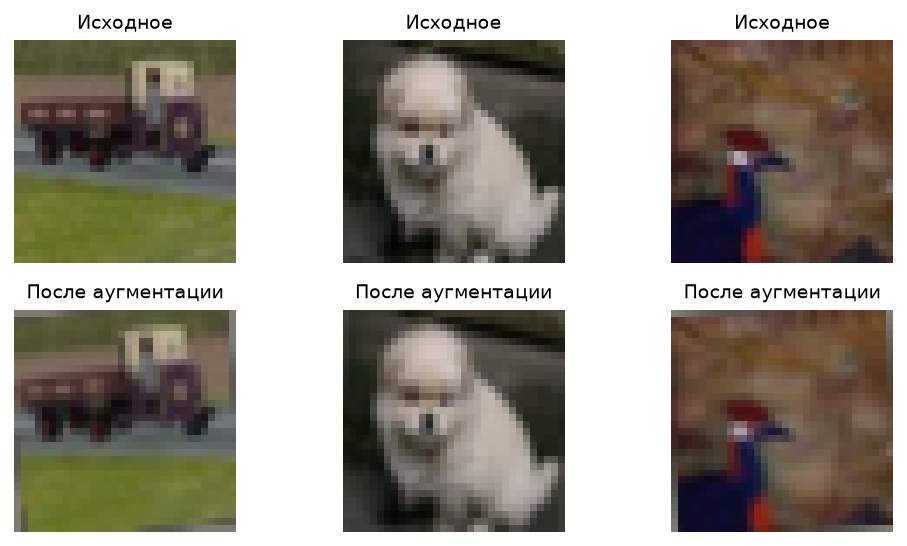

In [20]:
rotation_transform = v2.RandomApply([
    v2.RandomRotation(10, interpolation=v2.InterpolationMode.BILINEAR, fill=fill),
], p=0.5)
show_examples(ds_train, rotation_transform)

In [21]:
run_experiment("Rotation", rotation_transform)

Rotation: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3263
Эпоха 25/100: val_accuracy=0.5306
Эпоха 50/100: val_accuracy=0.5588
Эпоха 75/100: val_accuracy=0.5694
Эпоха 100/100: val_accuracy=0.5758
Best epoch = 100, best val_acc = 0.5758


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Rotation,57.58,100


### Масштабирование

С вероятностью 0,5 немного уменьшаем или увеличиваем объект. Масштаб выбирается от 0,9 до 1,1, размер самой картинки остаётся 32×32.

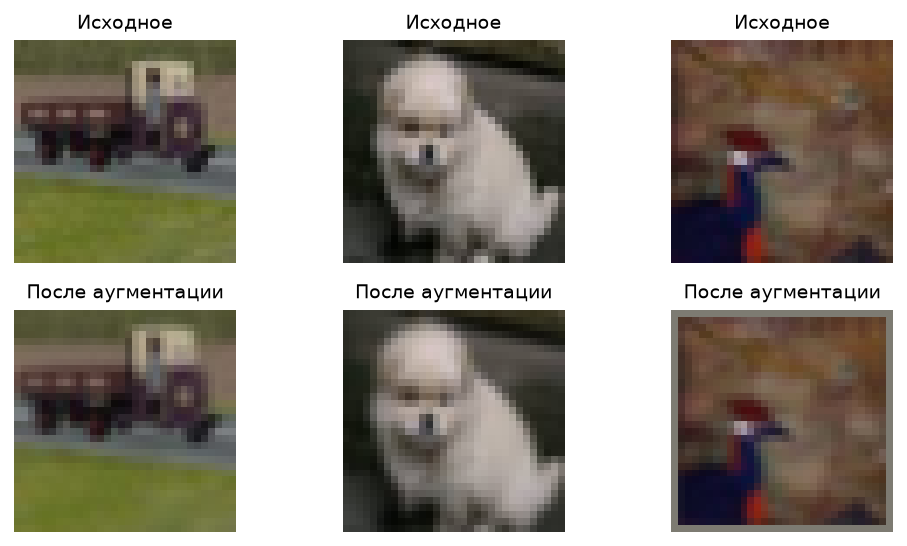

In [22]:
scale_transform = v2.RandomApply([
    v2.RandomAffine(
        degrees=0, scale=(0.9, 1.1),
        interpolation=v2.InterpolationMode.BILINEAR, fill=fill,
    ),
], p=0.5)
show_examples(ds_train, scale_transform)

In [23]:
run_experiment("Scale", scale_transform)

Scale: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3254
Эпоха 25/100: val_accuracy=0.5325
Эпоха 50/100: val_accuracy=0.5608
Эпоха 75/100: val_accuracy=0.5687
Эпоха 100/100: val_accuracy=0.5701
Best epoch = 87, best val_acc = 0.5739


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Scale,57.39,87


### Маскирование участка

С вероятностью 0,25 закрываем небольшой прямоугольник средним цветом train. Он занимает от 2 до 8% площади картинки.

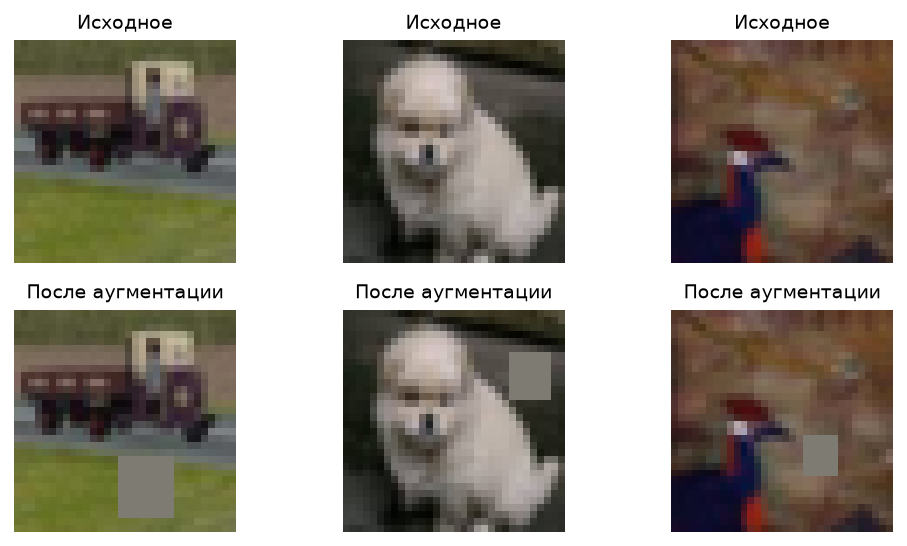

In [24]:
erasing_transform = v2.RandomErasing(
    p=0.25, scale=(0.02, 0.08), ratio=(0.75, 1.33), value=fill,
)
show_examples(ds_train, erasing_transform)

In [25]:
run_experiment("Random erasing", erasing_transform)

Random erasing: 100 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3245
Эпоха 25/100: val_accuracy=0.5309
Эпоха 50/100: val_accuracy=0.5594
Эпоха 75/100: val_accuracy=0.5678
Эпоха 100/100: val_accuracy=0.5762
Best epoch = 100, best val_acc = 0.5762


,Вариант,"Val accuracy, %",Лучшая эпоха
0,Random erasing,57.62,100


### Что видно за 100 эпох

Посмотрим на лучшую validation accuracy и результат последней эпохи. В колонке «Тренд val» сравниваются два последних отрезка по 10 эпох: из среднего последних 10 вычитается среднее предыдущих 10. Разница указана в процентных пунктах. Значение помогает понятьнасколько интенсивно продолжает расти метрика.

Выберем до четырёх вариантов для более долгой проверки. Посмотрим не только на лидеров, но и на кривые: вариант с меньшей accuracy может ещё заметно расти.

In [26]:
experiment_table(results_dir, epochs=SCREEN_EPOCHS, stage="single")

,Вариант,"Лучшая val, %","Val в конце, %","Тренд val, п.п.",Лучшая эпоха,Эпох
1,Horizontal flip,59.48,59.37,0.235,98,100
2,Crop,59.01,58.75,0.520,99,100
8,Random erasing,57.62,57.62,0.156,100,100
6,Rotation,57.58,57.58,0.238,100,100
3,Brightness,57.49,57.49,0.209,100,100
7,Scale,57.39,57.01,0.093,87,100
5,Saturation,57.18,57.18,0.045,100,100
0,Без аугментаций,57.11,57.11,0.097,100,100
4,Contrast,57.07,57.06,0.047,81,100


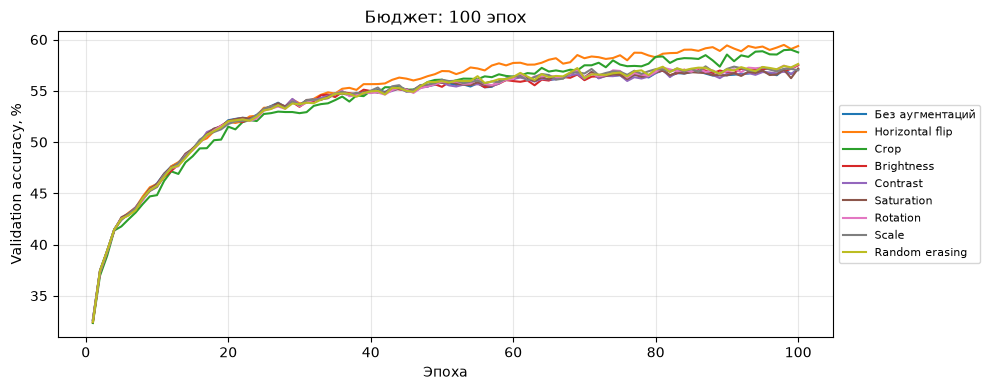

In [27]:
plot_learning_curves(results_dir, epochs=SCREEN_EPOCHS, stage="single")

Соберём операции в словарь, чтобы дальше выбирать их по названию. В сочетаниях они всегда применяются в одном порядке: crop, масштабирование, поворот, flip, изменения цвета и маскирование. Порядок добавления кандидатов в набор на это не влияет.

In [28]:
single_transforms = {
    "Crop": crop_transform, "Scale": scale_transform,
    "Rotation": rotation_transform, "Horizontal flip": flip_transform,
    "Brightness": brightness_transform, "Contrast": contrast_transform,
    "Saturation": saturation_transform, "Random erasing": erasing_transform,
}

## 2. Проверим кандидатов на 300 эпохах

В список ниже записываем до четырёх названий из таблицы. Если он пустой, обучение пропускается. Вместе с кандидатами обучим вариант без аугментаций, чтобы сравнить все результаты на 300 эпохах. Раннюю остановку пока не включаем.

Для следующего этапа выбраны четыре операции с лучшей validation accuracy на 100 эпохах: horizontal flip (59,48%), crop (59,01%), random erasing (57,62%) и rotation (57,58%). У всех четырёх средняя accuracy за последние 10 эпох выше, чем за предыдущие 10, поэтому проверим их при более длительном обучении.


In [ ]:
CANDIDATES = ["Horizontal flip", "Crop", "Random erasing", "Rotation"]

In [46]:
screened = completed_transforms(results_dir, single_transforms, epochs=SCREEN_EPOCHS, stage="single")
candidates = select_transforms(CANDIDATES, screened)
if candidates:
    run_experiment("Без аугментаций", baseline_transform, epochs=CHECK_EPOCHS)
    for name, transform in candidates.items():
        run_experiment(name, transform, epochs=CHECK_EPOCHS)

Без аугментаций: 300 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/300: val_accuracy=0.3262
Эпоха 25/300: val_accuracy=0.5321
Эпоха 50/300: val_accuracy=0.5584
Эпоха 75/300: val_accuracy=0.5652
Эпоха 100/300: val_accuracy=0.5711
Эпоха 125/300: val_accuracy=0.5664
Эпоха 150/300: val_accuracy=0.5590
Эпоха 175/300: val_accuracy=0.5625
Эпоха 200/300: val_accuracy=0.5533
Эпоха 225/300: val_accuracy=0.5487
Эпоха 250/300: val_accuracy=0.5363
Эпоха 275/300: val_accuracy=0.5356
Эпоха 300/300: val_accuracy=0.5303
Best epoch = 106, best val_acc = 0.5728
Horizontal flip: 300 эпох, этап single, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/300: val_accuracy=0.3238
Эпоха 25/300: val_accuracy=0.5335
Эпоха 50/300: val_accuracy=0.5693
Эпоха 75/300: val_accuracy=0.5847
Эпоха 100/300: val_accuracy=0.5937
Эпоха 125/300: val_accuracy=0.6000
Эпоха 150/300: val_

In [49]:
experiment_table(results_dir, epochs=CHECK_EPOCHS, stage="single")

,Вариант,"Лучшая val, %","Val в конце, %","Тренд val, п.п.",Лучшая эпоха,Эпох
11,Crop,63.42,63.06,0.103,299,300
10,Horizontal flip,61.36,61.17,0.090,276,300
13,Rotation,57.91,56.08,-0.058,177,300
12,Random erasing,57.80,55.51,-0.147,115,300
9,Без аугментаций,57.28,53.03,-0.180,106,300


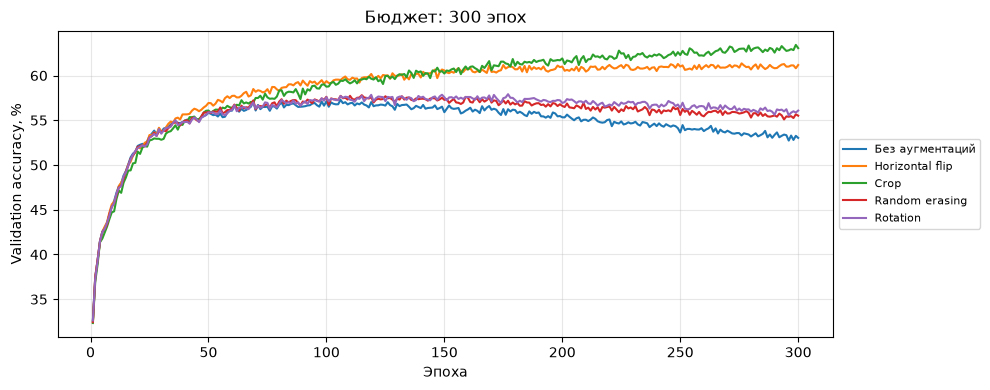

In [48]:
plot_learning_curves(results_dir, epochs=CHECK_EPOCHS, stage="single")

## 3. Соберём сочетания

Теперь попробуем объединять аугментации, добавляя их в порядке убывания полезности по результатам одиночных запусков на 300 эпохах: crop, horizontal flip, rotation и random erasing.

Сначала проверим crop + horizontal flip, затем добавим rotation, а после него random erasing. Так посмотрим, улучшается ли результат при добавлении каждой следующей операции.


In [ ]:
RANKED = ["Crop", "Horizontal flip", "Rotation", "Random erasing"]

In [55]:
eligible = completed_transforms(results_dir, single_transforms, epochs=CHECK_EPOCHS, stage="single")
combinations = cumulative_combinations(RANKED, eligible)
for name, transform in combinations.items():
    run_experiment(name, transform, stage="combo")

Crop + Horizontal flip: 100 эпох, этап combo, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3223
Эпоха 25/100: val_accuracy=0.5207
Эпоха 50/100: val_accuracy=0.5648
Эпоха 75/100: val_accuracy=0.5796
Эпоха 100/100: val_accuracy=0.5981
Best epoch = 99, best val_acc = 0.5981
Crop + Horizontal flip + Rotation: 100 эпох, этап combo, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3260
Эпоха 25/100: val_accuracy=0.5162
Эпоха 50/100: val_accuracy=0.5582
Эпоха 75/100: val_accuracy=0.5819
Эпоха 100/100: val_accuracy=0.5986
Best epoch = 99, best val_acc = 0.6029
Crop + Horizontal flip + Rotation + Random erasing: 100 эпох, этап combo, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/100: val_accuracy=0.3226
Эпоха 25/100: val_accuracy=0.5126
Эпоха 50/100: val_accuracy=0.

Каждое сочетание сначала обучаем 100 эпох. В таблице ниже сравним их с одиночными операциями и вариантом без аугментаций на тех же 100 эпохах.

In [56]:
experiment_table(results_dir, epochs=SCREEN_EPOCHS)

,Вариант,"Лучшая val, %","Val в конце, %","Тренд val, п.п.",Лучшая эпоха,Эпох
15,Crop + Horizontal flip + Rotation,60.29,59.86,0.632,99,100
14,Crop + Horizontal flip,59.81,59.81,0.445,99,100
16,Crop + Horizontal flip + Rotation + Random era...,59.66,59.40,0.487,99,100
1,Horizontal flip,59.48,59.37,0.235,98,100
2,Crop,59.01,58.75,0.520,99,100
8,Random erasing,57.62,57.62,0.156,100,100
6,Rotation,57.58,57.58,0.238,100,100
3,Brightness,57.49,57.49,0.209,100,100
7,Scale,57.39,57.01,0.093,87,100
5,Saturation,57.18,57.18,0.045,100,100


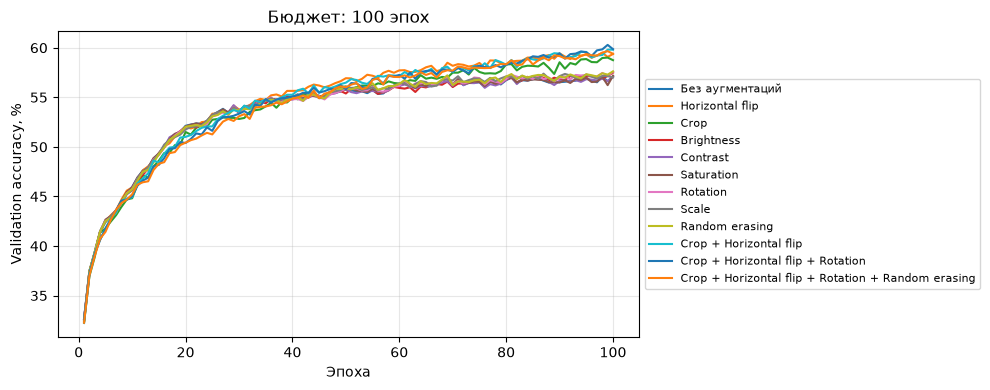

In [57]:
plot_learning_curves(results_dir, epochs=SCREEN_EPOCHS)

## 4. Полное обучение лучших вариантов

В полное обучение включаем все три сочетания: 
1. crop + flip
2. crop + flip + rotation
3. crop + flip + rotation + random erasing

На 100 эпохах они получили 59,81%, 60,29% и 59,66% соответственно. Разница между первым и третьим набором небольшая, поэтому проверим все три при более длительном обучении.

Для каждого варианта задаём до 1000 эпох и раннюю остановку после 50 эпох без улучшения validation accuracy.

In [61]:
FINALISTS = [
    "Crop + Horizontal flip",
    "Crop + Horizontal flip + Rotation",
    "Crop + Horizontal flip + Rotation + Random erasing",
]


In [62]:
checked_singles = completed_transforms(
    results_dir, {"Без аугментаций": baseline_transform, **single_transforms},
    epochs=CHECK_EPOCHS, stage="single",
)
checked_combos = completed_transforms(results_dir, combinations, epochs=SCREEN_EPOCHS, stage="combo")
finalists = select_transforms(FINALISTS, {**checked_singles, **checked_combos}, limit=3)
for name, transform in finalists.items():
    run_experiment(
        name, transform, stage="final", epochs=FINAL_EPOCHS, patience=FINAL_PATIENCE,
    )

Crop + Horizontal flip: 1000 эпох, этап final, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/1000: val_accuracy=0.3223
Эпоха 25/1000: val_accuracy=0.5207
Эпоха 50/1000: val_accuracy=0.5648
Эпоха 75/1000: val_accuracy=0.5796
Эпоха 100/1000: val_accuracy=0.5981
Эпоха 125/1000: val_accuracy=0.6078
Эпоха 150/1000: val_accuracy=0.6126
Эпоха 175/1000: val_accuracy=0.6171
Эпоха 200/1000: val_accuracy=0.6275
Эпоха 225/1000: val_accuracy=0.6313
Эпоха 250/1000: val_accuracy=0.6427
Эпоха 275/1000: val_accuracy=0.6474
Эпоха 300/1000: val_accuracy=0.6489
Эпоха 325/1000: val_accuracy=0.6652
Эпоха 350/1000: val_accuracy=0.6633
Эпоха 375/1000: val_accuracy=0.6708
Эпоха 400/1000: val_accuracy=0.6714
Эпоха 425/1000: val_accuracy=0.6733
Эпоха 450/1000: val_accuracy=0.6734
Эпоха 475/1000: val_accuracy=0.6790
Эпоха 500/1000: val_accuracy=0.6804
Эпоха 525/1000: val_accuracy=0.6787
Эпоха 550/1000: val_accuracy=0.6844
Ранняя остановка на эпохе 5

Crop + Horizontal flip + Rotation + Random erasing: 1000 эпох, этап final, seed 52. Метрики — в Aim.
Метрики Aim: http://127.0.0.1:43800 (интерфейс Aim нужно запустить отдельно)
Эпоха 1/1000: val_accuracy=0.3210
Эпоха 25/1000: val_accuracy=0.5241
Эпоха 50/1000: val_accuracy=0.5630
Эпоха 75/1000: val_accuracy=0.5760
Эпоха 100/1000: val_accuracy=0.5966
Эпоха 125/1000: val_accuracy=0.6087
Эпоха 150/1000: val_accuracy=0.6188
Эпоха 175/1000: val_accuracy=0.6187
Эпоха 200/1000: val_accuracy=0.6298
Эпоха 225/1000: val_accuracy=0.6357
Эпоха 250/1000: val_accuracy=0.6372
Эпоха 275/1000: val_accuracy=0.6446
Эпоха 300/1000: val_accuracy=0.6487
Эпоха 325/1000: val_accuracy=0.6572
Эпоха 350/1000: val_accuracy=0.6592
Эпоха 375/1000: val_accuracy=0.6632
Эпоха 400/1000: val_accuracy=0.6681
Эпоха 425/1000: val_accuracy=0.6678
Эпоха 450/1000: val_accuracy=0.6721
Эпоха 475/1000: val_accuracy=0.6688
Эпоха 500/1000: val_accuracy=0.6747
Эпоха 525/1000: val_accuracy=0.6737
Эпоха 550/1000: val_accuracy=0.6775

In [63]:
experiment_table(results_dir, epochs=FINAL_EPOCHS, stage="final")

,Вариант,"Лучшая val, %","Val в конце, %","Тренд val, п.п.",Лучшая эпоха,Эпох
18,Crop + Horizontal flip + Rotation,69.32,68.72,0.056,952,1000
17,Crop + Horizontal flip,68.95,68.48,-0.127,523,573
19,Crop + Horizontal flip + Rotation + Random era...,68.12,67.28,-0.085,540,590


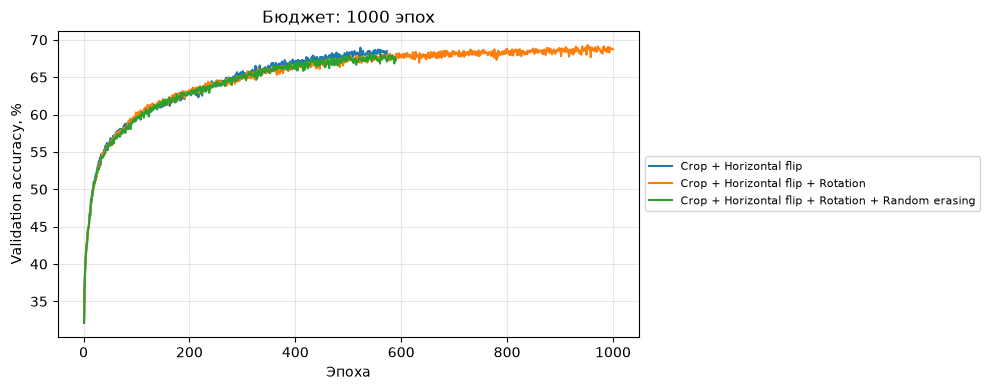

In [64]:
plot_learning_curves(results_dir, epochs=FINAL_EPOCHS, stage="final")

## Вывод

Лучший результат показал набор **crop + horizontal flip + rotation: 69,32% validation accuracy**. У crop + horizontal flip получилось **68,95%**, а добавление random erasing к набору с поворотом дало **68,12%**.

В этом эксперименте добавление поворота улучшило результат на 0,37 процентного пункта, а дополнительное random erasing его снизило. Для основного ноутбука LeNet выбираем **crop + horizontal flip + rotation**.
